### ANÁLISIS UNIVARIADO

Antes de realizar cualquier suposición, intento de modelar los datos, conclusión,etc...Lo primero que debemos hacer es analizar los datos

> **¿Dónde estamos en el flujo del EDA?**
> Este notebook cubre los pasos **02 – Conocer los datos** y **04 – Evaluar la calidad de los datos** (con foco en valores faltantes) del flujo visto en la teoría.
> Al terminar deberíamos poder responder: *¿cuántos datos tenemos, de qué tipo son y qué tan completos están?*

In [1]:
#Importamos la librería de pandas y asignamos un alias para simplificar su uso
import pandas as pd

In [2]:
#utilizamos el método read_csv() para levantar nuestro conjunto de datos en formato .csv
# Ojo en Colab: el archivo tiene que estar subido en el panel "Archivos" (ícono de carpeta, a la izquierda).
# Esos archivos son temporales: si el entorno se reinicia o se desconecta, hay que volver a subirlo.
# Si aparece FileNotFoundError, casi siempre es eso (o un error en el nombre del archivo).
# df es un DataFrame: una tabla donde cada fila es una observación y cada columna una variable.
df = pd.read_csv("sample_dataset.csv")

### ¿Qué datos vamos a analizar?

Trabajamos con una versión del dataset **Breast Cancer Wisconsin (Diagnostic)**, un conjunto de datos clásico de la Universidad de Wisconsin (1995), disponible públicamente en el repositorio UCI y en la librería scikit-learn.

- **Qué representa cada fila:** una muestra de una masa mamaria obtenida por punción (aspiración con aguja fina). La muestra se digitaliza como imagen y sobre ella se miden características de los **núcleos de las células**.
- **Qué representan las columnas:** se miden **10 características** de los núcleos (radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal), y cada una aparece en **3 versiones**:
    - `mean ...` → promedio de todos los núcleos de la imagen
    - `... error` → error estándar (cuánto varía esa medida entre núcleos)
    - `worst ...` → promedio de los 3 valores más grandes (los núcleos "peores")

    10 características × 3 versiones = **30 variables**, más la columna `target`.
- **`target` (variable objetivo):** el diagnóstico. `0` = maligno, `1` = benigno (codificación de scikit-learn).
- **Tipo de fuente:** **secundaria** — los datos fueron recolectados por otros y no tenemos control sobre cómo se midieron.

**Pregunta que guía el análisis (paso 01 del flujo):** ¿qué características de las células parecen diferenciar un tumor maligno de uno benigno?

> No hace falta saber medicina para hacer el EDA: lo importante es entender qué representa cada fila, qué mide cada columna y cuál es la variable que queremos explicar.

In [5]:
# Lo primero que quiero hacer es ver qué tiene este dataset, por lo cual utilizo el método head()
#para ver los primeros registros del conjunto de datos (por defecto, 5)
# Tip: df.tail() muestra los últimos y df.sample(5) muestra 5 filas al azar (útil si los datos vienen ordenados)
# NaN = "Not a Number": así muestra pandas un valor faltante
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,NaN,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.14710,0.2419,0.07871,...,17.33,NaN,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,NaN,NaN,0.0869,0.07017,NaN,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,NaN,0
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,NaN,NaN,NaN,0.05999,...,25.53,NaN,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,NaN,0.2597,0.09744,...,26.50,NaN,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,NaN,NaN,NaN,0.1328,0.1980,NaN,0.1809,NaN,...,16.67,152.2,1575.0,0.1374,NaN,0.4000,0.1625,0.2364,0.07678,0


Podemos observar varias cosas solo con esta aproximación:

1. Hay valores faltantes (aparecen como `NaN`).
2. Vemos que tenemos 31 columnas (variables): 30 características + `target`.
3. No sabemos el total de observaciones porque hicimos un `head()` (muestra de los primeros 5 registros).
4. La mayoría de las variables parecen ser numéricas.
5. Las escalas de las variables son diferentes: por ejemplo, `mean area` está en el orden de los cientos o miles, mientras que `mean smoothness` ronda 0,1. Esto va a importar cuando comparemos o grafiquemos variables juntas.

In [7]:
#Podemos agrandar la muestra de datos para ver los primeros 20 registros
df.head(20)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,NaN,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,NaN,2019.0,0.1622,0.6656,0.7119,0.26540,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,NaN,NaN,0.08690,0.07017,NaN,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.18600,0.2750,NaN,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,NaN,NaN,NaN,0.05999,...,25.53,NaN,1709.0,0.1444,0.4245,0.4504,0.24300,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,NaN,0.2597,0.09744,...,26.50,NaN,567.7,0.2098,0.8663,0.6869,0.25750,0.6638,0.17300,0
4,20.29,14.34,NaN,NaN,NaN,0.13280,0.19800,NaN,0.1809,NaN,...,16.67,152.20,1575.0,0.1374,NaN,0.4000,0.16250,0.2364,0.07678,0
5,12.45,15.70,82.57,NaN,0.12780,0.17000,0.15780,NaN,0.2087,0.07613,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.17410,0.3985,0.12440,0
6,18.25,NaN,119.60,NaN,NaN,0.10900,0.11270,0.07400,0.1794,0.05742,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.19320,NaN,0.08368,0
7,13.71,20.83,90.20,NaN,NaN,0.16450,0.09366,NaN,0.2196,0.07451,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.15560,0.3196,0.11510,0
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,...,30.73,106.20,739.3,0.1703,0.5401,NaN,0.20600,0.4378,0.10720,0
9,NaN,24.04,83.97,475.9,NaN,0.23960,0.22730,0.08543,NaN,0.08243,...,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.22100,0.4366,0.20750,0


In [ ]:
#Lo siguiente fundamental es analizar los tipos de datos con los que trabajamos para cada variable
# dtypes también es un atributo (sin paréntesis)
df.dtypes

,0
mean radius,float64
mean texture,float64
mean perimeter,float64
mean area,float64
mean smoothness,float64
mean compactness,float64
mean concavity,float64
mean concave points,float64
mean symmetry,float64
mean fractal dimension,float64


Vemos que la mayoría son del tipo flotante (`float64`, números con decimales), la variable objetivo es del tipo entero (`int64`) y `area error` es del tipo `object` (por lo general string o un tipo que no puede ser convertido a numérico directamente).

> **Atención: tipo de dato ≠ tipo de variable.** El *dtype* es cómo Python guarda el dato; el tipo de variable (categórica o numérica, ver lámina "Clasificación de variables") depende de lo que representa. Por ejemplo, `target` es `int64`, pero en realidad es una variable **categórica nominal**: el 0 y el 1 son etiquetas (maligno / benigno), no cantidades.

In [8]:
#Vamos a ver esa columna del tipo objeto, específicamente para ver de qué se trata
# Con un corchete df['col'] obtenemos una Serie (una sola columna);
# con doble corchete df[['col']] obtenemos un DataFrame (útil para seleccionar varias columnas)
df['area error']

,area error
0,A
1,A
2,A
3,A
4,NaN
...,...
564,A
565,A
566,A
567,A


In [11]:
#Si queremos ver los valores únicos/distintos de la variable utilizamos el método unique()
# Ojo: unique() muestra el NaN como un valor más; nunique() cuenta los distintos SIN contar los NaN
df['area error'].unique()
#df['area error'].nunique()

array(['A', nan, 'B', 'C'], dtype=object)

In [21]:
# value_counts() cuenta cuántas veces aparece cada valor; con dropna=False también cuenta los faltantes
df['area error'].value_counts(dropna=False)

,count
area error,
A,489
NaN,75
B,4
C,1


> **¿Qué significan A, B y C?** En el dataset original, `area error` es una variable **numérica**, como las demás columnas `... error`. En esta versión de clase fue modificada a propósito para practicar la detección de **problemas de calidad de datos**: es un caso de *tipo de dato incorrecto / valores inconsistentes* (ver lámina "Identificación de problemas en los datos"). En un caso real, acá habría que consultar a quien generó los datos qué significan esas categorías antes de decidir qué hacer.

Con esto tenemos una primera aproximación a lo que son nuestros datos, que nos permitió entender un poco más con qué nos estamos encontrando. Pero podemos seguir avanzando y explorando un poco más:

In [20]:
#Por ejemplo, podemos ver la cantidad de valores no nulos por cada columna con el método info()
# info() resume en un solo lugar: cantidad de filas (entries), nombre de cada columna,
# cuántos valores NO nulos tiene (Non-Null Count) y su tipo de dato (Dtype).
# Truco: si una columna tiene menos de 569 non-null, la diferencia son los faltantes.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              482 non-null    float64
 1   mean texture             492 non-null    float64
 2   mean perimeter           513 non-null    float64
 3   mean area                403 non-null    float64
 4   mean smoothness          384 non-null    float64
 5   mean compactness         480 non-null    float64
 6   mean concavity           439 non-null    float64
 7   mean concave points      382 non-null    float64
 8   mean symmetry            471 non-null    float64
 9   mean fractal dimension   504 non-null    float64
 10  radius error             475 non-null    float64
 11  texture error            434 non-null    float64
 12  perimeter error          381 non-null    float64
 13  area error               494 non-null    object 
 14  smoothness error         4

Algo fundamental en el análisis es entender qué tan limpio está nuestro conjunto de datos, y para eso el tema de los valores nulos o faltantes es clave. Pero, ¿cuántas observaciones totales tiene nuestro conjunto?

In [19]:
# shape es un ATRIBUTO (sin paréntesis): devuelve una tupla (filas, columnas)
# df.shape[0] = cantidad de filas | df.shape[1] = cantidad de columnas
df.shape

(569, 31)

Y como mencionábamos al principio de la clase, el uso de visualizaciones es de gran ayuda para comprender mejor lo que sucede con nuestros datos, por lo cual podemos graficar el comportamiento de los valores nulos :

In [18]:
# isna() devuelve una tabla del mismo tamaño que df, con True donde hay un faltante y False donde no.
# isnull() hace exactamente lo mismo (son sinónimos)
df.isna()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,True,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
1,False,False,False,False,True,True,False,False,True,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,True,True,True,False,...,False,True,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,True,False,False,...,False,True,False,False,False,False,False,False,False,False
4,False,False,True,True,True,False,False,True,False,True,...,False,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,False,False,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
565,True,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,True,False
566,False,False,False,True,False,False,True,False,False,False,...,False,False,False,False,True,False,False,False,False,False
567,False,False,False,False,False,False,False,False,False,True,...,True,False,False,False,False,False,False,False,False,False


True es cuando sí contiene un valor nulo, y False cuando no.
Ahora, si sumarizamos mediante `sum()`, podemos ver el total de nulos por cada columna (al sumar, Python trata `True` como 1 y `False` como 0):

In [17]:
df.isna().sum()

,0
mean radius,87
mean texture,77
mean perimeter,56
mean area,166
mean smoothness,185
mean compactness,89
mean concavity,130
mean concave points,187
mean symmetry,98
mean fractal dimension,65


In [16]:
# y si queremos la proporción, podemos dividir por el total de registros (df.shape[0] = 569)
# El resultado va de 0 a 1: multiplicando por 100 lo pasamos a porcentaje
# Atajo equivalente: df.isna().mean()
df.isna().sum()/df.shape[0]

,0
mean radius,0.152900
mean texture,0.135325
mean perimeter,0.098418
mean area,0.291740
mean smoothness,0.325132
mean compactness,0.156415
mean concavity,0.228471
mean concave points,0.328647
mean symmetry,0.172232
mean fractal dimension,0.114236


In [15]:
#y si queremos ordenarlos para ver cuál es el menor y el mayor:
# por defecto ordena de menor a mayor; con sort_values(ascending=False) queda de mayor a menor
(df.isna().sum()/df.shape[0]).sort_values()

,0
target,0.000000
mean perimeter,0.098418
worst area,0.100176
worst concavity,0.108963
concave points error,0.108963
mean fractal dimension,0.114236
worst concave points,0.130053
area error,0.131810
smoothness error,0.135325
mean texture,0.135325


<Axes: >

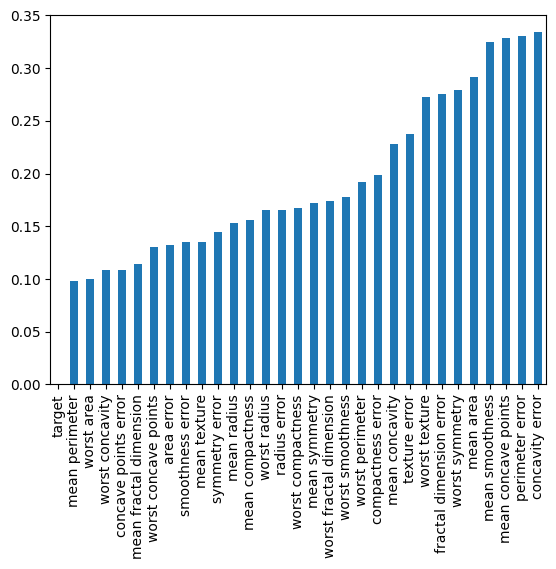

In [14]:
#podemos visualizar en un gráfico de barras (bar chart) lo analizado hasta aquí
# pandas usa matplotlib por detrás. Si los nombres del eje x se superponen: .plot(kind="bar", figsize=(12, 4))
(df.isna().sum()/df.shape[0]).sort_values().plot(kind="bar")

**¿Cómo leemos este gráfico?**

- `target` no tiene faltantes: buena noticia, porque es la variable que queremos explicar.
- El resto de las variables tiene entre ~10% y ~33% de faltantes (en las peores, un tercio de las filas no tiene dato).

**¿Y qué hacemos con los faltantes?** Por ahora, nada: en el EDA primero los **detectamos y medimos**. Después se decide si **eliminar**, **corregir** o **imputar** (por ejemplo, con la media o la mediana), según el caso (ver lámina "Identificación de problemas en los datos").

Pregunta para pensar: si elimináramos todas las filas que tienen al menos un faltante, ¿cuántas nos quedarían?

In [22]:
# dropna() elimina las filas con al menos un NaN. Comparemos con las 569 originales:
df.dropna().shape

(0, 31)

**¿Qué significa `(0, 31)`?** Que después de `dropna()` quedan **0 filas** (y las mismas 31 columnas): **todas** las filas tienen al menos un faltante en alguna columna.

¿Cómo puede ser, si ninguna columna supera el ~33% de faltantes? Porque los faltantes están repartidos al azar entre 30 columnas, y para que una fila "sobreviva" tiene que estar completa en **las 30 a la vez**:

- Una columna con 85% de datos completos parece "casi limpia".
- Pero 30 columnas así: 0,85 × 0,85 × … (30 veces) ≈ 0,8% de probabilidad de que una fila esté completa.
- Con los porcentajes reales de este dataset, esa probabilidad da cerca de **0,13%**: sobre 569 filas, se esperaría menos de 1 fila completa.

> **Conclusión:** eliminar filas con faltantes no siempre es una opción: acá nos quedaríamos sin datos. Por eso hay que evaluar alternativas: eliminar columnas con muchos faltantes, **imputar** (por ejemplo, con la media o la mediana) o eliminar filas solo según las columnas relevantes para nuestra pregunta, por ejemplo `df.dropna(subset=["mean radius", "target"])`.

Hasta acá tuvimos una primera aproximación muy general de nuestro conjunto de datos, en donde, resumiendo, lo que hicimos fue:

1) Cargamos nuestro conjunto de datos al notebook
2) vimos los primeros registros y columnas para ver de qué se trata
3) Vimos los tipos de datos de cada variable
4) Profundizamos sobre el tipo Object
5) Contamos los missing values de cada columna
6) Identificamos el total de registros y columnas del dataset
7) Calculamos el % de missings para cada variable
8) Los ordenamos de menor a mayor y visualizamos en un gráfico de barras